In [1]:
import sys
from pathlib import Path
sys.path.insert(0,str(Path.cwd()))
from unittest.mock import patch
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from matplotlib.figure import Figure
import pandas as pd

def forbidden(*args, **kwargs):
    raise RuntimeError("La auditoría prohíbe entrenar y escribir datasets")
_guards = [patch.object(KMeans, 'fit', forbidden), patch.object(RandomForestClassifier, 'fit', forbidden), patch.object(pd.DataFrame, 'to_parquet', forbidden), patch.object(pd.DataFrame, 'to_csv', forbidden), patch.object(Figure, 'savefig', lambda *a, **k: None)]
for _guard in _guards: _guard.start()


# Figuras de detecciones y categorías estadísticas FIRMS

Sin detecciones es la categoría previa de conteo cero, no un clúster de K-Means. Clúster 1 (1 detección), Clúster 2 (2–4) y Clúster 3 (5–173) siguen el orden ascendente de los centroides. No indican riesgo ni intensidad de incendio. Se usan las asignaciones oficiales guardadas, sin ajustar modelos.

Los PNG se guardan a 300 dpi en `results/figuras_informe_actualizadas/`. La numeración corresponde a los pies de figura del Word consultado en modo lectura. El mapa se conserva desde su salida original, sin descargar cartografía.

In [2]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.class_labels import display_frame
from src.visual_style import COLORS
OUTPUT = ROOT / "results/figuras_informe_actualizadas"
OUTPUT.mkdir(parents=True, exist_ok=True)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)

In [3]:
RUTA_DATOS = "data/processed/firms_open_meteo_weekly/open_meteo_firms_weekly_target_available.parquet"
TRAIN_INICIO = pd.Timestamp("2018-01-01")
TRAIN_FIN = pd.Timestamp("2023-12-31")

datos = pd.read_parquet(ROOT / RUTA_DATOS)
datos["fecha_inicio_semana"] = pd.to_datetime(datos["fecha_inicio_semana"], errors="raise")
columnas_requeridas = {"fecha_inicio_semana", "cantidad_detecciones", "nivel_actividad_firms"}
assert columnas_requeridas.issubset(datos.columns)
assert datos[list(columnas_requeridas)].isna().sum().sum() == 0
assert datos["cantidad_detecciones"].ge(0).all()

train = datos.loc[datos["fecha_inicio_semana"].between(TRAIN_INICIO, TRAIN_FIN)].copy()
train_positivos = train.loc[train["cantidad_detecciones"].gt(0)].copy()

pd.DataFrame({
    "particion": ["train completo", "train positivo", "ceros separados", "fuera del ajuste"],
    "observaciones": [len(train), len(train_positivos), train["cantidad_detecciones"].eq(0).sum(), len(datos) - len(train)],
    "fecha_min": [train["fecha_inicio_semana"].min(), train_positivos["fecha_inicio_semana"].min(), train["fecha_inicio_semana"].min(), datos.loc[~datos.index.isin(train.index), "fecha_inicio_semana"].min()],
    "fecha_max": [train["fecha_inicio_semana"].max(), train_positivos["fecha_inicio_semana"].max(), train["fecha_inicio_semana"].max(), datos.loc[~datos.index.isin(train.index), "fecha_inicio_semana"].max()]
})

,particion,observaciones,fecha_min,fecha_max
0,train completo,5947,2018-01-01,2023-12-25
1,train positivo,2331,2018-01-01,2023-12-25
2,ceros separados,3616,2018-01-01,2023-12-25
3,fuera del ajuste,1976,2024-01-01,2025-12-22


In [4]:
datos.head().drop(columns=[c for c in datos.columns if c.startswith("nivel_actividad_firms")])

,departamento,departamento_iso,fecha_inicio_semana,fecha_fin_semana,anio,numero_semana,n_dias_esperados,n_dias_observados,cobertura_temporal_pct,cobertura_espacial_min_pct,precipitation_days_weekly,temperature_2m_max_mean_weekly,temperature_2m_max_weekly,temperature_2m_min_mean_weekly,temperature_2m_min_weekly,relative_humidity_2m_min_mean_weekly,relative_humidity_2m_min_weekly,relative_humidity_2m_max_mean_weekly,relative_humidity_2m_max_weekly,wind_speed_10m_max_mean_weekly,wind_speed_10m_max_weekly,precipitation_sum_weekly,precipitation_max_daily_weekly,et0_fao_evapotranspiration_sum_weekly,et0_fao_evapotranspiration_max_daily_weekly,wind_direction_10m_resultant_length_spatial_daily_mean_weekly,wind_direction_10m_dominant_circular_mean_weekly,wind_direction_10m_resultant_length_weekly,cantidad_detecciones,target_firms_disponible
0,Artigas,UY-AR,2018-01-01,2018-01-07,2018,1,7,7,100.0,100.0,3,30.764286,35.8,19.607143,15.7,32.959184,22,73.765306,96,6.566735,10.11,7.007143,4.585714,51.444286,9.26,0.996843,170.548873,0.296492,0,True
1,Artigas,UY-AR,2018-01-08,2018-01-14,2018,2,7,7,100.0,100.0,5,31.731633,35.7,22.044898,16.7,44.836735,22,78.765306,98,5.319592,7.43,32.842857,19.464286,43.183571,8.86,0.990082,82.423858,0.716303,0,True
2,Artigas,UY-AR,2018-01-15,2018-01-21,2018,3,7,7,100.0,100.0,6,29.744898,32.9,20.202041,17.3,44.469388,26,86.744898,97,5.492347,7.51,17.071429,15.364286,37.437143,7.35,0.996518,111.423557,0.674849,0,True
3,Artigas,UY-AR,2018-01-22,2018-01-28,2018,4,7,7,100.0,100.0,3,30.010204,33.3,20.647959,16.5,52.051020,37,90.755102,100,5.493673,7.62,25.335714,23.857143,38.801429,7.59,0.993956,92.446674,0.374700,0,True
4,Artigas,UY-AR,2018-01-29,2018-02-04,2018,5,7,7,100.0,100.0,0,31.524490,35.2,20.045918,16.4,37.132653,22,80.051020,91,5.431224,6.59,0.000000,0.000000,48.926429,7.70,0.998478,100.069495,0.974888,0,True


In [5]:
datos.shape

(7923, 32)

In [6]:
cantidad_cero = (datos["cantidad_detecciones"] == 0).sum()
cantidad_mayor_cero = (datos["cantidad_detecciones"] > 0).sum()

print("Cantidad = 0:", cantidad_cero)
print("Cantidad > 0:", cantidad_mayor_cero)

Cantidad = 0: 4967
Cantidad > 0: 2956


In [7]:
datos[["departamento"]].value_counts()

departamento  
Artigas           417
Canelones         417
Cerro Largo       417
Colonia           417
Durazno           417
Flores            417
Florida           417
Lavalleja         417
Maldonado         417
Montevideo        417
Paysandú          417
Rivera            417
Rocha             417
Río Negro         417
Salto             417
San José          417
Soriano           417
Tacuarembó        417
Treinta y Tres    417
Name: count, dtype: int64

## Algunos gráficos

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Configuración tipográfica
plt.rcParams.update({
    "font.family": ["Liberation Sans", "DejaVu Sans"],
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "savefig.dpi": 300,
})

# Paleta de trabajo: reemplazar por los HEX oficiales UTEC
UTEC_AZUL = "#00C7FF"
UTEC_CELESTE = "#80E3FF"
UTEC_GRIS = "#BABABB"
UTEC_CLARO = "#E5F9FF"
UTEC_OSCURO = "#343A40"

PALETA_UTEC = [
    UTEC_AZUL,
    UTEC_CELESTE,
    UTEC_GRIS,
    UTEC_OSCURO
]

sns.set_style("whitegrid", {
    "grid.color": "#E5E5E5",
    "grid.alpha": 0.4
})

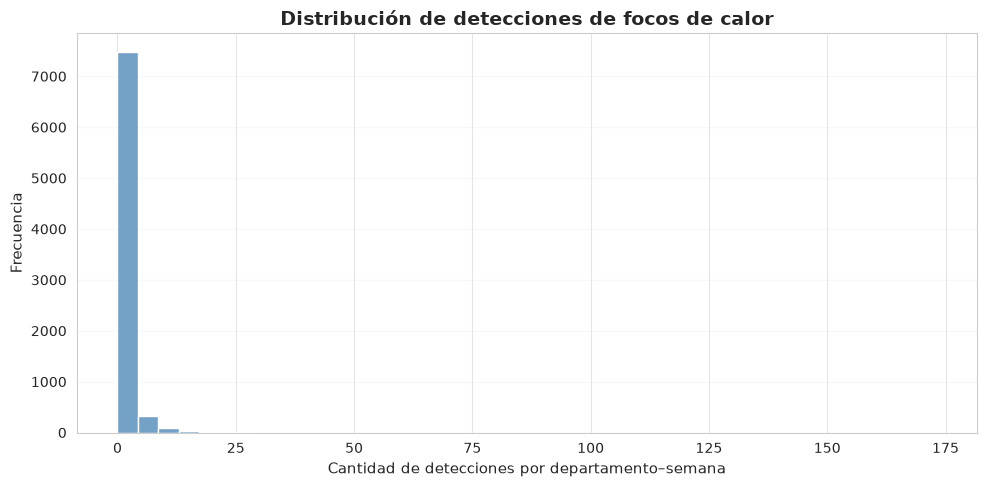

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(
    data=datos,
    x="cantidad_detecciones",
    bins=40,
    color="steelblue"
)

plt.title("Distribución de detecciones de focos de calor")
plt.xlabel("Cantidad de detecciones por departamento–semana")
plt.ylabel("Frecuencia")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
q1 = datos["cantidad_detecciones"].quantile(0.25)
q3 = datos["cantidad_detecciones"].quantile(0.75)

iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr

print("Límite superior de valores atípicos:", limite_superior)

Límite superior de valores atípicos: 2.5


In [11]:
positivos = datos.loc[
    datos["cantidad_detecciones"] > 0,
    "cantidad_detecciones"
]

q1 = positivos.quantile(0.25)
q3 = positivos.quantile(0.75)

iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr

print("Q1:", q1)
print("Mediana:", positivos.median())
print("Q3:", q3)
print("Límite superior:", limite_superior)
print("Máximo:", positivos.max())

Q1: 1.0
Mediana: 2.0
Q3: 3.0
Límite superior: 6.0
Máximo: 173


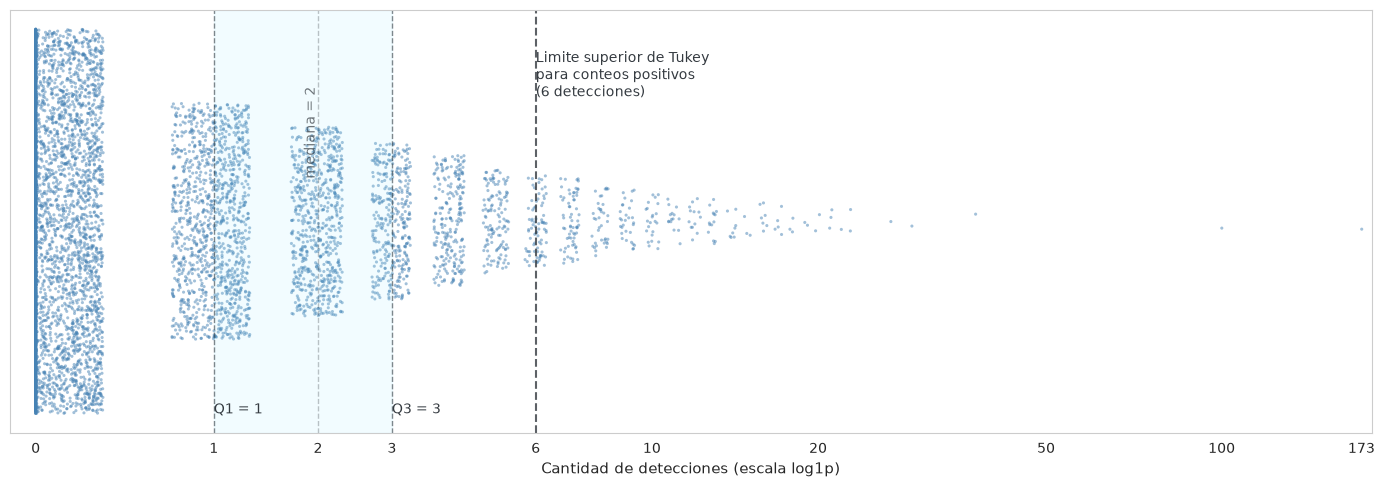

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# Mismas estadísticas de la celda 11, calculadas sobre conteos positivos.
positivos_fig2 = datos.loc[datos["cantidad_detecciones"].gt(0), "cantidad_detecciones"]
q1_fig2 = positivos_fig2.quantile(0.25)
mediana_fig2 = positivos_fig2.median()
q3_fig2 = positivos_fig2.quantile(0.75)
iqr_fig2 = q3_fig2 - q1_fig2
limite_fig2 = q3_fig2 + 1.5 * iqr_fig2

x = datos["cantidad_detecciones"].dropna().to_numpy()

# Frecuencia de cada cantidad de detecciones
valores, conteos = np.unique(x, return_counts=True)
frecuencias = dict(zip(valores, conteos))

# Dispersión vertical proporcional a la frecuencia
np.random.seed(42)

amplitud = np.array([
    (frecuencias[v] / conteos.max()) ** 0.35
    for v in x
])

y_jitter = np.random.uniform(-1, 1, len(x)) * amplitud
x_jitter = x + np.random.uniform(-0.30, 0.30, len(x))

fig, ax = plt.subplots(figsize=(14, 5))

# Transformar las posiciones horizontales
x_log = np.log1p(x_jitter.clip(min=0))

ax.scatter(
    x_log,    y_jitter,
    s=5,    alpha=0.50,
    color="steelblue",
    edgecolors="none"
)


ax.set_xticks(np.log1p([0, 1, 2, 3, 6, 10, 20, 50, 100, 173]))
ax.set_xticklabels(["0", "1", "2", "3", "6", "10", "20", "50", "100", "173"])

ax.set_xlim(-0.1, np.log1p(180))
ax.set_xlabel("Cantidad de detecciones (escala log1p)")


ax.set_ylabel("")
ax.set_yticks([])
ax.grid(False)

#ax.spines["left"].set_visible(False)

ax.axvline(
    x=np.log1p(limite_fig2),
    color=UTEC_OSCURO,
    linestyle="--",
    linewidth=1.5,
    alpha=0.8
)

ax.text(
    np.log1p(limite_fig2), 0.65,
    "Limite superior de Tukey""\n"
    "para conteos positivos""\n"
    f"({limite_fig2:g} detecciones)",
    color=UTEC_OSCURO,
    fontsize=10
)
# Cuartiles y mediana de los conteos positivos, igual que el umbral de Tukey.
#----------------------q1
ax.axvline(
    x=np.log1p(q1_fig2),
    color=UTEC_OSCURO,
    linestyle="--",
    linewidth=1,
    alpha=0.6
)
ax.text(
    np.log1p(q1_fig2), -1,
    f"Q1 = {q1_fig2:g}",
    color=UTEC_OSCURO,
    fontsize=10
)
#-----------------------------
#----------------------q3
ax.axvline(
    x=np.log1p(q3_fig2),
    color=UTEC_OSCURO,
    linestyle="--",
    linewidth=1,
    alpha=0.6
)
ax.text(
    np.log1p(q3_fig2), -1,
    f"Q3 = {q3_fig2:g}",
    color=UTEC_OSCURO,
    fontsize=10
)
#-----------------------------mediana
ax.axvline(
    x=np.log1p(mediana_fig2),
    color=UTEC_OSCURO,
    linestyle="--",
    linewidth=1,
    alpha=0.3
)
ax.text(
    np.log1p(mediana_fig2),0.7,
    f"mediana = {mediana_fig2:g}", rotation=90, va="top", ha="right",
    color=UTEC_OSCURO,
    fontsize=10,alpha=0.7
)
#-----------------------------

ax.axvspan(
    np.log1p(q1_fig2), np.log1p(q3_fig2),
    color=UTEC_CELESTE,
    alpha=0.10
)

#ax.set_title("Distribución de detecciones de focos de calor por departamento-semana")
plt.savefig(
    OUTPUT / "figura_02_distribucion_detecciones.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)
plt.tight_layout()
plt.show()

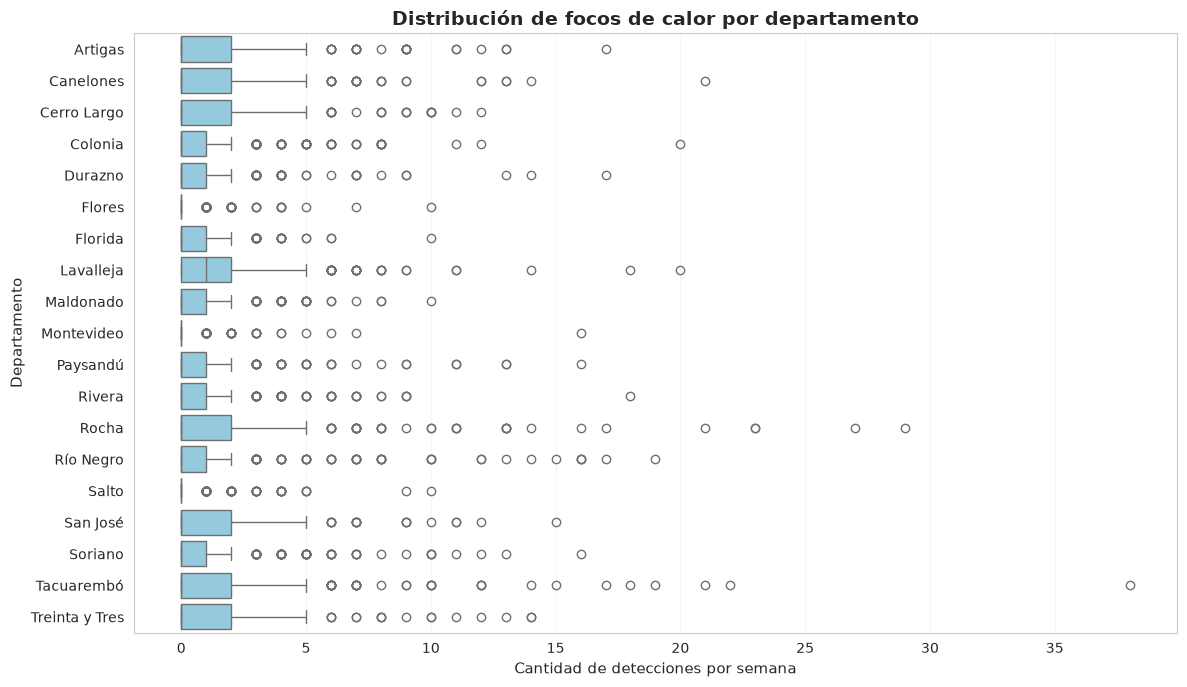

In [13]:
plt.figure(figsize=(12, 7))

sns.boxplot(
    data=datos[datos["cantidad_detecciones"]<50],
    x="cantidad_detecciones",
    y="departamento",
    color="skyblue"
)

plt.title("Distribución de focos de calor por departamento")
plt.xlabel("Cantidad de detecciones por semana")
plt.ylabel("Departamento")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

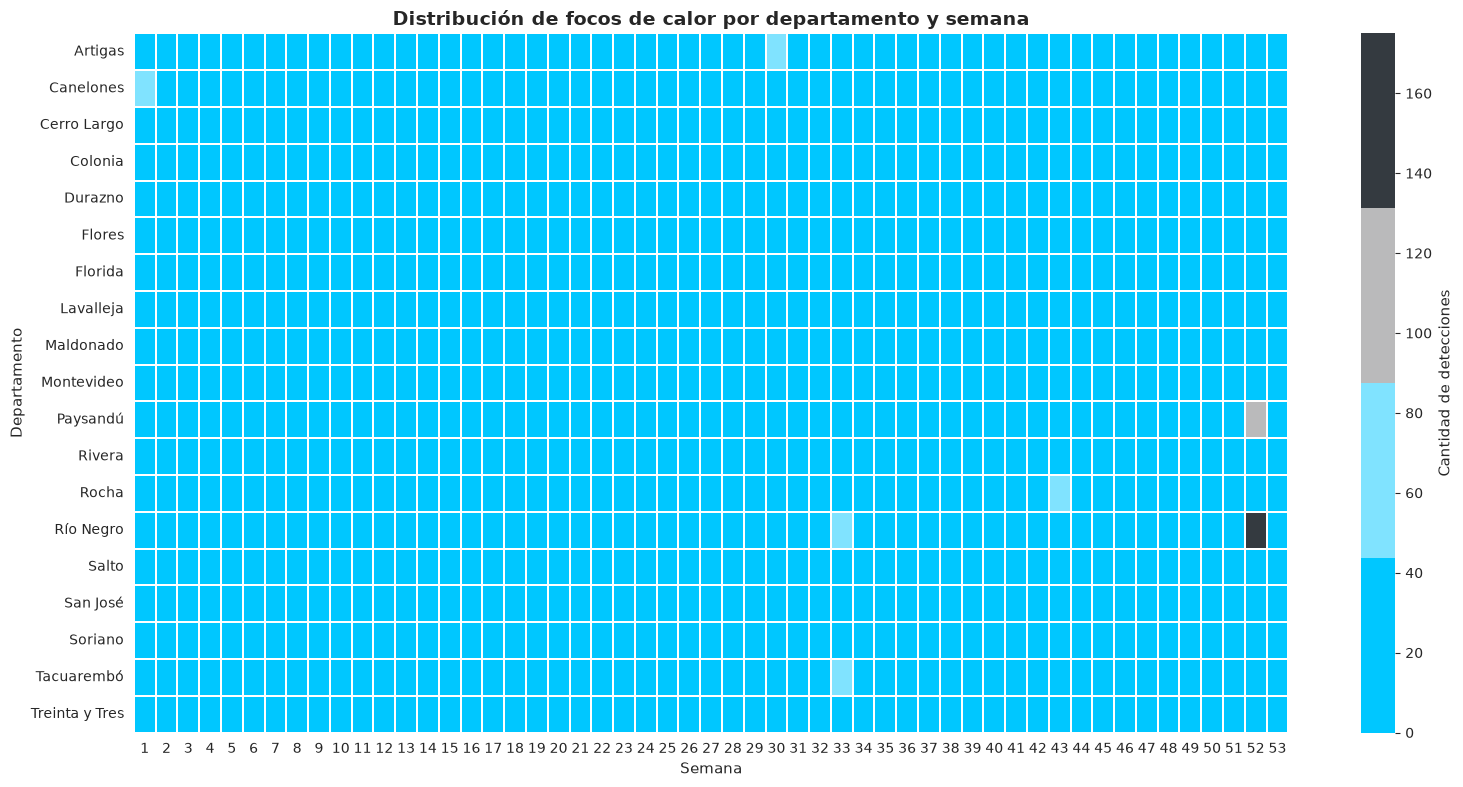

In [14]:
import pandas as pd

# Convertir la columna a numérica
datos["cantidad_detecciones"] = pd.to_numeric(
    datos["cantidad_detecciones"],
    errors="coerce"
)

# Crear tabla para el mapa de calor
tabla_heatmap = datos.pivot_table(
    index="departamento",
    columns="numero_semana",
    values="cantidad_detecciones",
    aggfunc="sum",
    fill_value=0
)

tabla_heatmap = tabla_heatmap.sort_index(axis=1)

# Generar gráfico
plt.figure(figsize=(16, 8))

sns.heatmap(
    tabla_heatmap.astype(float),
    cmap=PALETA_UTEC,
    linewidths=0.2,
    cbar_kws={"label": "Cantidad de detecciones"}
)

plt.title("Distribución de focos de calor por departamento y semana")
plt.xlabel("Semana")
plt.ylabel("Departamento")
plt.tight_layout()
plt.show()

# Analisis de variables meteorologicas por cluster

In [15]:
file = ROOT / "data/processed/modelado/dataset_modelado_nivel_actividad_firms.parquet"
data = display_frame(pd.read_parquet(file))
data.shape

(7923, 19)

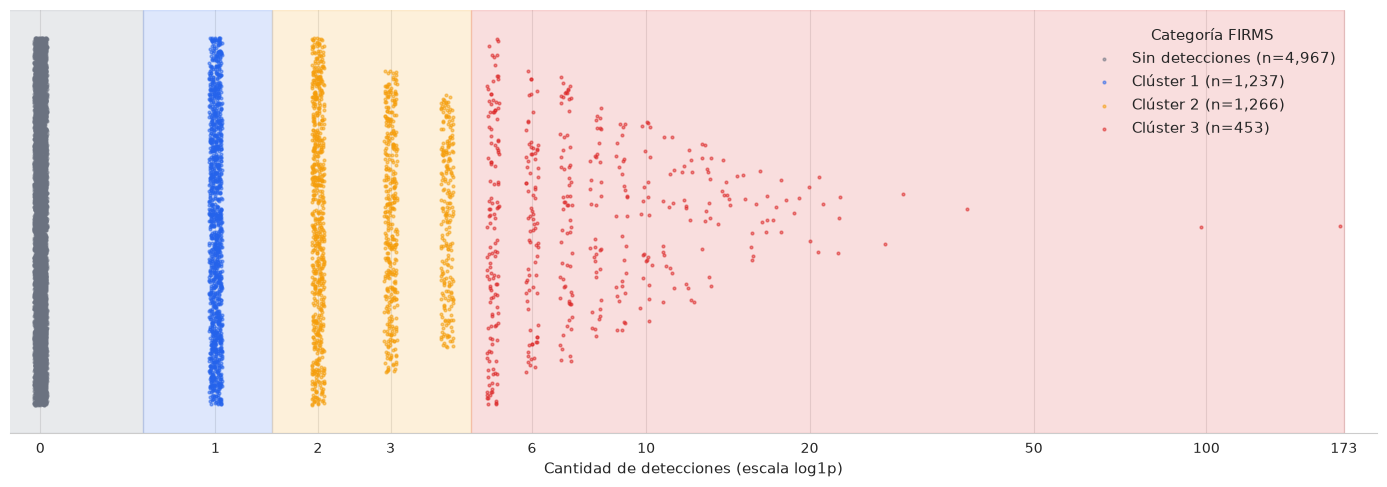

In [16]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

# Separar los cuatro categorías
sin_actividad = data.loc[
    data["nivel_actividad_firms"] == "Sin detecciones",
    "cantidad_detecciones"
].dropna()

bajo = data.loc[
    data["nivel_actividad_firms"] == "Clúster 1",
    "cantidad_detecciones"
].dropna()

moderado = data.loc[
    data["nivel_actividad_firms"] == "Clúster 2",
    "cantidad_detecciones"
].dropna()

alto = data.loc[
    data["nivel_actividad_firms"] == "Clúster 3",
    "cantidad_detecciones"
].dropna()


# Frecuencias para controlar la dispersión vertical
f0 = sin_actividad.value_counts()
f1 = bajo.value_counts()
f2 = moderado.value_counts()
f3 = alto.value_counts()

# Coordenadas con jitter horizontal y vertical
x0 = np.log1p(sin_actividad.to_numpy()) + rng.uniform(-0.025, 0.025, len(sin_actividad))
y0 = rng.uniform(-1, 1, len(sin_actividad)) * (sin_actividad.map(f0) / f0.max()).to_numpy() ** 0.35

x1 = np.log1p(bajo.to_numpy()) + rng.uniform(-0.025, 0.025, len(bajo))
y1 = rng.uniform(-1, 1, len(bajo)) * (bajo.map(f1) / f1.max()).to_numpy() ** 0.35

x2 = np.log1p(moderado.to_numpy()) + rng.uniform(-0.025, 0.025, len(moderado))
y2 = rng.uniform(-1, 1, len(moderado)) * (moderado.map(f2) / f2.max()).to_numpy() ** 0.35

x3 = np.log1p(alto.to_numpy()) + rng.uniform(-0.025, 0.025, len(alto))
y3 = rng.uniform(-1, 1, len(alto)) * (alto.map(f3) / f3.max()).to_numpy() ** 0.35


# Crear figura
fig, ax = plt.subplots(figsize=(14, 5))

# ---------------------------------
# ÁREAS SOMBREADAS (EDITABLES)
# Límites entre los rangos oficiales ya asignados; no reconstruyen el target
# ---------------------------------

ax.axvspan(-1, np.log1p(0.5),
           color=COLORS["Sin detecciones"], alpha=0.15)

ax.axvspan(np.log1p(0.5), np.log1p(1.5),
           color=COLORS["Clúster 1"], alpha=0.15)

ax.axvspan(np.log1p(1.5), np.log1p(4.5),
           color=COLORS["Clúster 2"], alpha=0.15)

ax.axvspan(np.log1p(4.5), np.log1p(173),
           color=COLORS["Clúster 3"], alpha=0.15)


# ---------------------------------
# PUNTOS DE CADA CATEGORÍA
# ---------------------------------

ax.scatter(x0, y0, s=4, alpha=0.5,
           color=COLORS["Sin detecciones"],
           label=f"Sin detecciones (n={len(sin_actividad):,})")

ax.scatter(x1, y1, s=4, alpha=0.5,
           color=COLORS["Clúster 1"],
           label=f"Clúster 1 (n={len(bajo):,})")

ax.scatter(x2, y2, s=4, alpha=0.5,
           color=COLORS["Clúster 2"],
           label=f"Clúster 2 (n={len(moderado):,})")

ax.scatter(x3, y3, s=4, alpha=0.5,
           color=COLORS["Clúster 3"],
           label=f"Clúster 3 (n={len(alto):,})")


# ---------------------------------
# FORMATO
# ---------------------------------

ticks = [0, 1, 2, 3, 6, 10, 20, 50, 100, 173]

ax.set_xticks(np.log1p(ticks))
ax.set_xticklabels(ticks)

ax.set_xlim(-0.12, np.log1p(175) + 0.12)
ax.set_ylim(-1.15, 1.15)

ax.set_xlabel("Cantidad de detecciones (escala log1p)", fontsize=11)
ax.set_yticks([])

ax.legend(
    title="Categoría FIRMS",
    loc="upper right",
    bbox_to_anchor=(0.98, 0.99),
    frameon=False
)

ax.spines[["top", "right", "left"]].set_visible(False)

plt.savefig(
    OUTPUT / "figura_03_distribucion_categorias_firms.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)
plt.tight_layout()
plt.show()

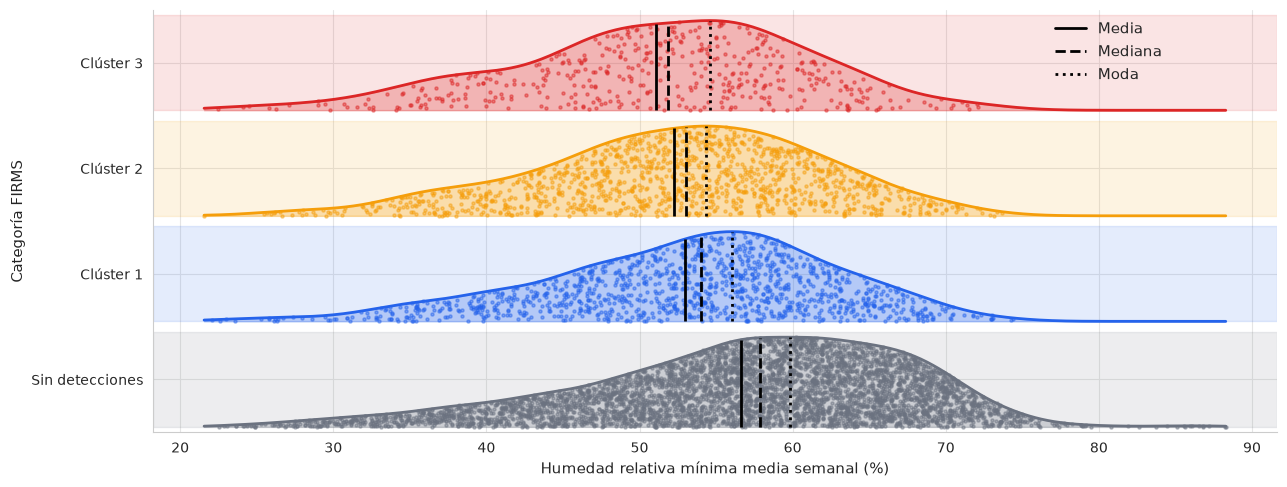

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
import numpy as np
from matplotlib.lines import Line2D


rng = np.random.default_rng(42)
#'mes', 'relative_humidity_2m_min_mean_weekly', 'wind_speed_10m_max_mean_weekly', 'precipitation_sum_weekly',
 #'cantidad_detecciones_lag1', 'cantidad_detecciones_lag2', 'cantidad_detecciones_lag3', 'cantidad_detecciones_lag4',
 #      'promedio_detecciones_ultimas_4_semanas',   'max_detecciones_ultimas_4_semanas', 'semanas_con_actividad_ultimas_4',
 #      'cantidad_detecciones', 'nivel_actividad_firms','nivel_actividad_firms_codigo'

variable = "relative_humidity_2m_min_mean_weekly"

# Datos por cluster
v0 = data.loc[data["nivel_actividad_firms"] == "Sin detecciones", variable].dropna()
v1 = data.loc[data["nivel_actividad_firms"] == "Clúster 1", variable].dropna()
v2 = data.loc[data["nivel_actividad_firms"] == "Clúster 2", variable].dropna()
v3 = data.loc[data["nivel_actividad_firms"] == "Clúster 3", variable].dropna()


# Dispersión horizontal
# Dispersión horizontal
jitter_x = 0.02

x0 = v0.to_numpy() + rng.uniform(-jitter_x, jitter_x, len(v0))
x1 = v1.to_numpy() + rng.uniform(-jitter_x, jitter_x, len(v1))
x2 = v2.to_numpy() + rng.uniform(-jitter_x, jitter_x, len(v2))
x3 = v3.to_numpy() + rng.uniform(-jitter_x, jitter_x, len(v3))
# Valores del eje X
xx = np.linspace(
    min(v0.min(), v1.min(), v2.min(), v3.min()),
    max(v0.max(), v1.max(), v2.max(), v3.max()),
    500
)
# Densidades KDE
kde0 = gaussian_kde(v0)
kde1 = gaussian_kde(v1)
kde2 = gaussian_kde(v2)
kde3 = gaussian_kde(v3)

# Normalizar la altura de cada curva
d0 = kde0(xx)
d1 = kde1(xx)
d2 = kde2(xx)
d3 = kde3(xx)

d0 = d0 / d0.max() * 0.85
d1 = d1 / d1.max() * 0.85
d2 = d2 / d2.max() * 0.85
d3 = d3 / d3.max() * 0.85

# Altura de la curva KDE en la posición de cada punto
h0 = np.interp(x0, xx, d0, left=0, right=0)
h1 = np.interp(x1, xx, d1, left=0, right=0)
h2 = np.interp(x2, xx, d2, left=0, right=0)
h3 = np.interp(x3, xx, d3, left=0, right=0)

# Distribuir los puntos dentro de cada curva
y0 = -0.45 + rng.uniform(0, 1, len(v0)) * h0
y1 =  0.55 + rng.uniform(0, 1, len(v1)) * h1
y2 =  1.55 + rng.uniform(0, 1, len(v2)) * h2
y3 =  2.55 + rng.uniform(0, 1, len(v3)) * h3



fig, ax = plt.subplots(figsize=(13, 5))

# Franjas sombreadas por cluster
ax.axhspan(-0.45, 0.45, color=COLORS["Sin detecciones"], alpha=0.12)
ax.axhspan(0.55, 1.45, color=COLORS["Clúster 1"], alpha=0.12)
ax.axhspan(1.55, 2.45, color=COLORS["Clúster 2"], alpha=0.12)
ax.axhspan(2.55, 3.45, color=COLORS["Clúster 3"], alpha=0.12)

# Puntos
ax.scatter(x0, y0, s=5, alpha=0.45, color=COLORS["Sin detecciones"], zorder=3)
ax.scatter(x1, y1, s=5, alpha=0.45, color=COLORS["Clúster 1"], zorder=3)
ax.scatter(x2, y2, s=5, alpha=0.45, color=COLORS["Clúster 2"], zorder=3)
ax.scatter(x3, y3, s=5, alpha=0.45, color=COLORS["Clúster 3"], zorder=3)



# Distribuciones simétricas por cluster

# Sin detecciones
ax.fill_between(xx, -0.45, -0.45 + d0, color=COLORS["Sin detecciones"], alpha=0.25)
ax.plot(xx, -0.45 + d0, color=COLORS["Sin detecciones"], lw=2)

# Clúster 1
ax.fill_between(xx, 0.55, 0.55 + d1, color=COLORS["Clúster 1"], alpha=0.25)
ax.plot(xx, 0.55 + d1, color=COLORS["Clúster 1"], lw=2)

# Clúster 2
ax.fill_between(xx, 1.55, 1.55 + d2, color=COLORS["Clúster 2"], alpha=0.25)
ax.plot(xx, 1.55 + d2, color=COLORS["Clúster 2"], lw=2)

# Clúster 3
ax.fill_between(xx, 2.55, 2.55 + d3, color=COLORS["Clúster 3"], alpha=0.25)
ax.plot(xx, 2.55 + d3, color=COLORS["Clúster 3"], lw=2)


media0, mediana0 = v0.mean(), v0.median()
media1, mediana1 = v1.mean(), v1.median()
media2, mediana2 = v2.mean(), v2.median()
media3, mediana3 = v3.mean(), v3.median()

# Sin detecciones
ax.vlines(media0, -0.45, -0.45 + np.interp(media0, xx, d0),
          color="black", linewidth=2, zorder=5)

ax.vlines(mediana0, -0.45, -0.45 + np.interp(mediana0, xx, d0),
          color="black", linestyle="--", linewidth=2, zorder=5)

# Clúster 1
ax.vlines(media1, 0.55, 0.55 + np.interp(media1, xx, d1),
          color="black", linewidth=2, zorder=5)

ax.vlines(mediana1, 0.55, 0.55 + np.interp(mediana1, xx, d1),
          color="black", linestyle="--", linewidth=2, zorder=5)

# Clúster 2
ax.vlines(media2, 1.55, 1.55 + np.interp(media2, xx, d2),
          color="black", linewidth=2, zorder=5)

ax.vlines(mediana2, 1.55, 1.55 + np.interp(mediana2, xx, d2),
          color="black", linestyle="--", linewidth=2, zorder=5)

# Clúster 3
ax.vlines(media3, 2.55, 2.55 + np.interp(media3, xx, d3),
          color="black", linewidth=2, zorder=5)

ax.vlines(mediana3, 2.55, 2.55 + np.interp(mediana3, xx, d3),
          color="black", linestyle="--", linewidth=2, zorder=5)

# Modas estimadas mediante KDE
moda0 = xx[np.argmax(d0)]
moda1 = xx[np.argmax(d1)]
moda2 = xx[np.argmax(d2)]
moda3 = xx[np.argmax(d3)]

# Líneas verticales de moda
ax.vlines(moda0, -0.45, -0.45 + d0.max(),
          color="black", linestyle=":", linewidth=2, zorder=6)

ax.vlines(moda1, 0.55, 0.55 + d1.max(),
          color="black", linestyle=":", linewidth=2, zorder=6)

ax.vlines(moda2, 1.55, 1.55 + d2.max(),
          color="black", linestyle=":", linewidth=2, zorder=6)

ax.vlines(moda3, 2.55, 2.55 + d3.max(),
          color="black", linestyle=":", linewidth=2, zorder=6)
# Formato
ax.set_yticks([0, 1, 2, 3])
ax.set_yticklabels(["Sin detecciones", "Clúster 1", "Clúster 2", "Clúster 3"])

ax.set_ylim(-0.5, 3.5)
#ax.set_xlim(4,7)

ax.set_xlabel("Humedad relativa mínima media semanal (%)")
ax.set_ylabel("Categoría FIRMS")

ax.spines[["top", "right"]].set_visible(False)

leyenda = [
    Line2D([0], [0], color="black", lw=2, label="Media"),
    Line2D([0], [0], color="black", lw=2, ls="--", label="Mediana"),
    Line2D([0], [0], color="black", lw=2, ls=":", label="Moda")
]

ax.legend(
    handles=leyenda,
    loc="center",
    bbox_to_anchor=(0.85, 0.90),
    frameon=False
)
plt.savefig(    OUTPUT / "figura_07_distribucion_humedad.png",    dpi=300,    bbox_inches="tight",    facecolor="white")
plt.tight_layout()
plt.show()

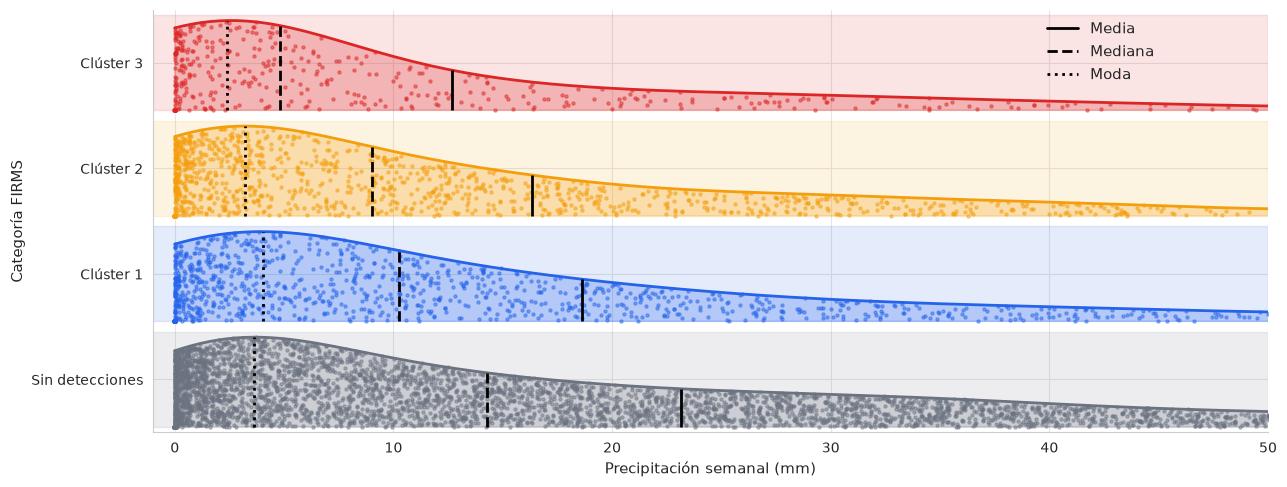

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
import numpy as np
from matplotlib.lines import Line2D


rng = np.random.default_rng(42)
#'mes', 'relative_humidity_2m_min_mean_weekly', 'wind_speed_10m_max_mean_weekly', 'precipitation_sum_weekly',
 #'cantidad_detecciones_lag1', 'cantidad_detecciones_lag2', 'cantidad_detecciones_lag3', 'cantidad_detecciones_lag4',
 #      'promedio_detecciones_ultimas_4_semanas',   'max_detecciones_ultimas_4_semanas', 'semanas_con_actividad_ultimas_4',
 #      'cantidad_detecciones', 'nivel_actividad_firms','nivel_actividad_firms_codigo'

variable = "precipitation_sum_weekly"

# Datos por cluster
v0 = data.loc[data["nivel_actividad_firms"] == "Sin detecciones", variable].dropna()
v1 = data.loc[data["nivel_actividad_firms"] == "Clúster 1", variable].dropna()
v2 = data.loc[data["nivel_actividad_firms"] == "Clúster 2", variable].dropna()
v3 = data.loc[data["nivel_actividad_firms"] == "Clúster 3", variable].dropna()


# Dispersión horizontal
# Dispersión horizontal
jitter_x = 0.02

x0 = v0.to_numpy() + rng.uniform(-jitter_x, jitter_x, len(v0))
x1 = v1.to_numpy() + rng.uniform(-jitter_x, jitter_x, len(v1))
x2 = v2.to_numpy() + rng.uniform(-jitter_x, jitter_x, len(v2))
x3 = v3.to_numpy() + rng.uniform(-jitter_x, jitter_x, len(v3))
# Valores del eje X
xx = np.linspace(
    min(v0.min(), v1.min(), v2.min(), v3.min()),
    max(v0.max(), v1.max(), v2.max(), v3.max()),
    500
)
# Densidades KDE
kde0 = gaussian_kde(v0)
kde1 = gaussian_kde(v1)
kde2 = gaussian_kde(v2)
kde3 = gaussian_kde(v3)

# Normalizar la altura de cada curva
d0 = kde0(xx)
d1 = kde1(xx)
d2 = kde2(xx)
d3 = kde3(xx)

d0 = d0 / d0.max() * 0.85
d1 = d1 / d1.max() * 0.85
d2 = d2 / d2.max() * 0.85
d3 = d3 / d3.max() * 0.85

# Altura de la curva KDE en la posición de cada punto
h0 = np.interp(x0, xx, d0, left=0, right=0)
h1 = np.interp(x1, xx, d1, left=0, right=0)
h2 = np.interp(x2, xx, d2, left=0, right=0)
h3 = np.interp(x3, xx, d3, left=0, right=0)

# Distribuir los puntos dentro de cada curva
y0 = -0.45 + rng.uniform(0, 1, len(v0)) * h0
y1 =  0.55 + rng.uniform(0, 1, len(v1)) * h1
y2 =  1.55 + rng.uniform(0, 1, len(v2)) * h2
y3 =  2.55 + rng.uniform(0, 1, len(v3)) * h3



fig, ax = plt.subplots(figsize=(13, 5))

# Franjas sombreadas por cluster
ax.axhspan(-0.45, 0.45, color=COLORS["Sin detecciones"], alpha=0.12)
ax.axhspan(0.55, 1.45, color=COLORS["Clúster 1"], alpha=0.12)
ax.axhspan(1.55, 2.45, color=COLORS["Clúster 2"], alpha=0.12)
ax.axhspan(2.55, 3.45, color=COLORS["Clúster 3"], alpha=0.12)

# Puntos
ax.scatter(x0, y0, s=5, alpha=0.45, color=COLORS["Sin detecciones"], zorder=3)
ax.scatter(x1, y1, s=5, alpha=0.45, color=COLORS["Clúster 1"], zorder=3)
ax.scatter(x2, y2, s=5, alpha=0.45, color=COLORS["Clúster 2"], zorder=3)
ax.scatter(x3, y3, s=5, alpha=0.45, color=COLORS["Clúster 3"], zorder=3)



# Distribuciones simétricas por cluster

# Sin detecciones
ax.fill_between(xx, -0.45, -0.45 + d0, color=COLORS["Sin detecciones"], alpha=0.25)
ax.plot(xx, -0.45 + d0, color=COLORS["Sin detecciones"], lw=2)

# Clúster 1
ax.fill_between(xx, 0.55, 0.55 + d1, color=COLORS["Clúster 1"], alpha=0.25)
ax.plot(xx, 0.55 + d1, color=COLORS["Clúster 1"], lw=2)

# Clúster 2
ax.fill_between(xx, 1.55, 1.55 + d2, color=COLORS["Clúster 2"], alpha=0.25)
ax.plot(xx, 1.55 + d2, color=COLORS["Clúster 2"], lw=2)

# Clúster 3
ax.fill_between(xx, 2.55, 2.55 + d3, color=COLORS["Clúster 3"], alpha=0.25)
ax.plot(xx, 2.55 + d3, color=COLORS["Clúster 3"], lw=2)


media0, mediana0 = v0.mean(), v0.median()
media1, mediana1 = v1.mean(), v1.median()
media2, mediana2 = v2.mean(), v2.median()
media3, mediana3 = v3.mean(), v3.median()

# Sin detecciones
ax.vlines(media0, -0.45, -0.45 + np.interp(media0, xx, d0),
          color="black", linewidth=2, zorder=5)

ax.vlines(mediana0, -0.45, -0.45 + np.interp(mediana0, xx, d0),
          color="black", linestyle="--", linewidth=2, zorder=5)

# Clúster 1
ax.vlines(media1, 0.55, 0.55 + np.interp(media1, xx, d1),
          color="black", linewidth=2, zorder=5)

ax.vlines(mediana1, 0.55, 0.55 + np.interp(mediana1, xx, d1),
          color="black", linestyle="--", linewidth=2, zorder=5)

# Clúster 2
ax.vlines(media2, 1.55, 1.55 + np.interp(media2, xx, d2),
          color="black", linewidth=2, zorder=5)

ax.vlines(mediana2, 1.55, 1.55 + np.interp(mediana2, xx, d2),
          color="black", linestyle="--", linewidth=2, zorder=5)

# Clúster 3
ax.vlines(media3, 2.55, 2.55 + np.interp(media3, xx, d3),
          color="black", linewidth=2, zorder=5)

ax.vlines(mediana3, 2.55, 2.55 + np.interp(mediana3, xx, d3),
          color="black", linestyle="--", linewidth=2, zorder=5)

# Modas estimadas mediante KDE
moda0 = xx[np.argmax(d0)]
moda1 = xx[np.argmax(d1)]
moda2 = xx[np.argmax(d2)]
moda3 = xx[np.argmax(d3)]

# Líneas verticales de moda
ax.vlines(moda0, -0.45, -0.45 + d0.max(),
          color="black", linestyle=":", linewidth=2, zorder=6)

ax.vlines(moda1, 0.55, 0.55 + d1.max(),
          color="black", linestyle=":", linewidth=2, zorder=6)

ax.vlines(moda2, 1.55, 1.55 + d2.max(),
          color="black", linestyle=":", linewidth=2, zorder=6)

ax.vlines(moda3, 2.55, 2.55 + d3.max(),
          color="black", linestyle=":", linewidth=2, zorder=6)
# Formato
ax.set_yticks([0, 1, 2, 3])
ax.set_yticklabels(["Sin detecciones", "Clúster 1", "Clúster 2", "Clúster 3"])

ax.set_ylim(-0.5, 3.5)
ax.set_xlim(-1,50)

ax.set_xlabel("Precipitación semanal (mm)")
ax.set_ylabel("Categoría FIRMS")

ax.spines[["top", "right"]].set_visible(False)

leyenda = [
    Line2D([0], [0], color="black", lw=2, label="Media"),
    Line2D([0], [0], color="black", lw=2, ls="--", label="Mediana"),
    Line2D([0], [0], color="black", lw=2, ls=":", label="Moda")
]

ax.legend(
    handles=leyenda,
    loc="center",
    bbox_to_anchor=(0.85, 0.90),
    frameon=False
)
plt.savefig(    OUTPUT / "figura_08_distribucion_precipitacion.png",    dpi=300,    bbox_inches="tight",    facecolor="white")
plt.tight_layout()
plt.show()

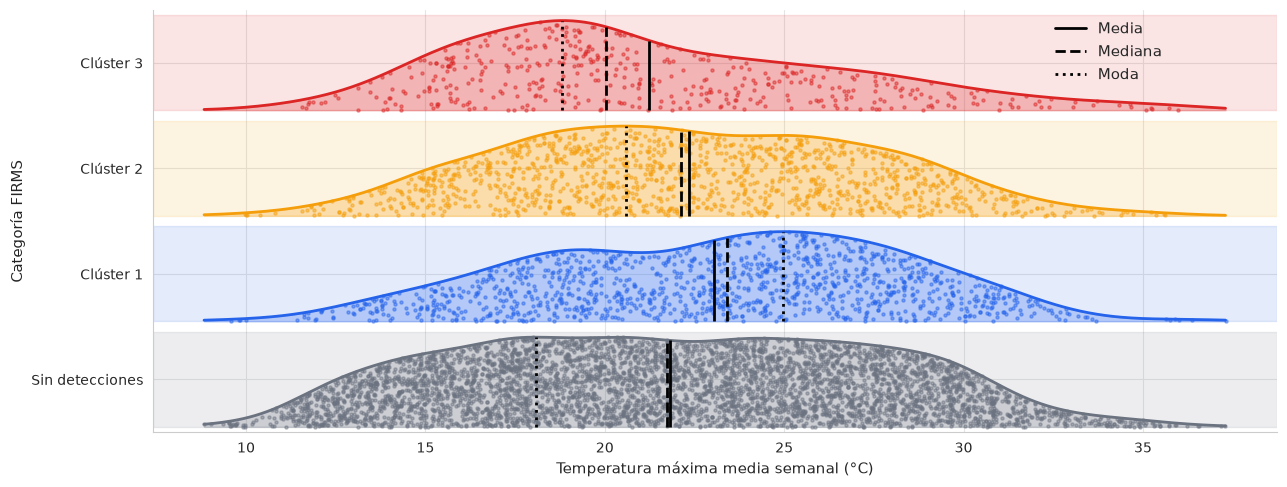

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
import numpy as np
from matplotlib.lines import Line2D


rng = np.random.default_rng(42)
#'mes', 'relative_humidity_2m_min_mean_weekly', 'wind_speed_10m_max_mean_weekly', 'precipitation_sum_weekly',
 #'cantidad_detecciones_lag1', 'cantidad_detecciones_lag2', 'cantidad_detecciones_lag3', 'cantidad_detecciones_lag4',
 #      'promedio_detecciones_ultimas_4_semanas',   'max_detecciones_ultimas_4_semanas', 'semanas_con_actividad_ultimas_4',
 #      'cantidad_detecciones', 'nivel_actividad_firms','nivel_actividad_firms_codigo'

variable = "temperature_2m_max_mean_weekly"

# Datos por cluster
v0 = data.loc[data["nivel_actividad_firms"] == "Sin detecciones", variable].dropna()
v1 = data.loc[data["nivel_actividad_firms"] == "Clúster 1", variable].dropna()
v2 = data.loc[data["nivel_actividad_firms"] == "Clúster 2", variable].dropna()
v3 = data.loc[data["nivel_actividad_firms"] == "Clúster 3", variable].dropna()


# Dispersión horizontal
# Dispersión horizontal
jitter_x = 0.02

x0 = v0.to_numpy() + rng.uniform(-jitter_x, jitter_x, len(v0))
x1 = v1.to_numpy() + rng.uniform(-jitter_x, jitter_x, len(v1))
x2 = v2.to_numpy() + rng.uniform(-jitter_x, jitter_x, len(v2))
x3 = v3.to_numpy() + rng.uniform(-jitter_x, jitter_x, len(v3))
# Valores del eje X
xx = np.linspace(
    min(v0.min(), v1.min(), v2.min(), v3.min()),
    max(v0.max(), v1.max(), v2.max(), v3.max()),
    500
)
# Densidades KDE
kde0 = gaussian_kde(v0)
kde1 = gaussian_kde(v1)
kde2 = gaussian_kde(v2)
kde3 = gaussian_kde(v3)

# Normalizar la altura de cada curva
d0 = kde0(xx)
d1 = kde1(xx)
d2 = kde2(xx)
d3 = kde3(xx)

d0 = d0 / d0.max() * 0.85
d1 = d1 / d1.max() * 0.85
d2 = d2 / d2.max() * 0.85
d3 = d3 / d3.max() * 0.85

# Altura de la curva KDE en la posición de cada punto
h0 = np.interp(x0, xx, d0, left=0, right=0)
h1 = np.interp(x1, xx, d1, left=0, right=0)
h2 = np.interp(x2, xx, d2, left=0, right=0)
h3 = np.interp(x3, xx, d3, left=0, right=0)

# Distribuir los puntos dentro de cada curva
y0 = -0.45 + rng.uniform(0, 1, len(v0)) * h0
y1 =  0.55 + rng.uniform(0, 1, len(v1)) * h1
y2 =  1.55 + rng.uniform(0, 1, len(v2)) * h2
y3 =  2.55 + rng.uniform(0, 1, len(v3)) * h3



fig, ax = plt.subplots(figsize=(13, 5))

# Franjas sombreadas por cluster
ax.axhspan(-0.45, 0.45, color=COLORS["Sin detecciones"], alpha=0.12)
ax.axhspan(0.55, 1.45, color=COLORS["Clúster 1"], alpha=0.12)
ax.axhspan(1.55, 2.45, color=COLORS["Clúster 2"], alpha=0.12)
ax.axhspan(2.55, 3.45, color=COLORS["Clúster 3"], alpha=0.12)

# Puntos
ax.scatter(x0, y0, s=5, alpha=0.45, color=COLORS["Sin detecciones"], zorder=3)
ax.scatter(x1, y1, s=5, alpha=0.45, color=COLORS["Clúster 1"], zorder=3)
ax.scatter(x2, y2, s=5, alpha=0.45, color=COLORS["Clúster 2"], zorder=3)
ax.scatter(x3, y3, s=5, alpha=0.45, color=COLORS["Clúster 3"], zorder=3)



# Distribuciones simétricas por cluster

# Sin detecciones
ax.fill_between(xx, -0.45, -0.45 + d0, color=COLORS["Sin detecciones"], alpha=0.25)
ax.plot(xx, -0.45 + d0, color=COLORS["Sin detecciones"], lw=2)

# Clúster 1
ax.fill_between(xx, 0.55, 0.55 + d1, color=COLORS["Clúster 1"], alpha=0.25)
ax.plot(xx, 0.55 + d1, color=COLORS["Clúster 1"], lw=2)

# Clúster 2
ax.fill_between(xx, 1.55, 1.55 + d2, color=COLORS["Clúster 2"], alpha=0.25)
ax.plot(xx, 1.55 + d2, color=COLORS["Clúster 2"], lw=2)

# Clúster 3
ax.fill_between(xx, 2.55, 2.55 + d3, color=COLORS["Clúster 3"], alpha=0.25)
ax.plot(xx, 2.55 + d3, color=COLORS["Clúster 3"], lw=2)


media0, mediana0 = v0.mean(), v0.median()
media1, mediana1 = v1.mean(), v1.median()
media2, mediana2 = v2.mean(), v2.median()
media3, mediana3 = v3.mean(), v3.median()

# Sin detecciones
ax.vlines(media0, -0.45, -0.45 + np.interp(media0, xx, d0),
          color="black", linewidth=2, zorder=5)

ax.vlines(mediana0, -0.45, -0.45 + np.interp(mediana0, xx, d0),
          color="black", linestyle="--", linewidth=2, zorder=5)

# Clúster 1
ax.vlines(media1, 0.55, 0.55 + np.interp(media1, xx, d1),
          color="black", linewidth=2, zorder=5)

ax.vlines(mediana1, 0.55, 0.55 + np.interp(mediana1, xx, d1),
          color="black", linestyle="--", linewidth=2, zorder=5)

# Clúster 2
ax.vlines(media2, 1.55, 1.55 + np.interp(media2, xx, d2),
          color="black", linewidth=2, zorder=5)

ax.vlines(mediana2, 1.55, 1.55 + np.interp(mediana2, xx, d2),
          color="black", linestyle="--", linewidth=2, zorder=5)

# Clúster 3
ax.vlines(media3, 2.55, 2.55 + np.interp(media3, xx, d3),
          color="black", linewidth=2, zorder=5)

ax.vlines(mediana3, 2.55, 2.55 + np.interp(mediana3, xx, d3),
          color="black", linestyle="--", linewidth=2, zorder=5)

# Modas estimadas mediante KDE
moda0 = xx[np.argmax(d0)]
moda1 = xx[np.argmax(d1)]
moda2 = xx[np.argmax(d2)]
moda3 = xx[np.argmax(d3)]

# Líneas verticales de moda
ax.vlines(moda0, -0.45, -0.45 + d0.max(),
          color="black", linestyle=":", linewidth=2, zorder=6)

ax.vlines(moda1, 0.55, 0.55 + d1.max(),
          color="black", linestyle=":", linewidth=2, zorder=6)

ax.vlines(moda2, 1.55, 1.55 + d2.max(),
          color="black", linestyle=":", linewidth=2, zorder=6)

ax.vlines(moda3, 2.55, 2.55 + d3.max(),
          color="black", linestyle=":", linewidth=2, zorder=6)
# Formato
ax.set_yticks([0, 1, 2, 3])
ax.set_yticklabels(["Sin detecciones", "Clúster 1", "Clúster 2", "Clúster 3"])

ax.set_ylim(-0.5, 3.5)
#ax.set_xlim(-1,50)

ax.set_xlabel("Temperatura máxima media semanal (°C)")
ax.set_ylabel("Categoría FIRMS")

ax.spines[["top", "right"]].set_visible(False)

leyenda = [
    Line2D([0], [0], color="black", lw=2, label="Media"),
    Line2D([0], [0], color="black", lw=2, ls="--", label="Mediana"),
    Line2D([0], [0], color="black", lw=2, ls=":", label="Moda")
]

ax.legend(
    handles=leyenda,
    loc="center",
    bbox_to_anchor=(0.85, 0.90),
    frameon=False
)
plt.savefig(    OUTPUT / "figura_06_distribucion_temperatura.png",    dpi=300,    bbox_inches="tight",    facecolor="white")
plt.tight_layout()
plt.show()

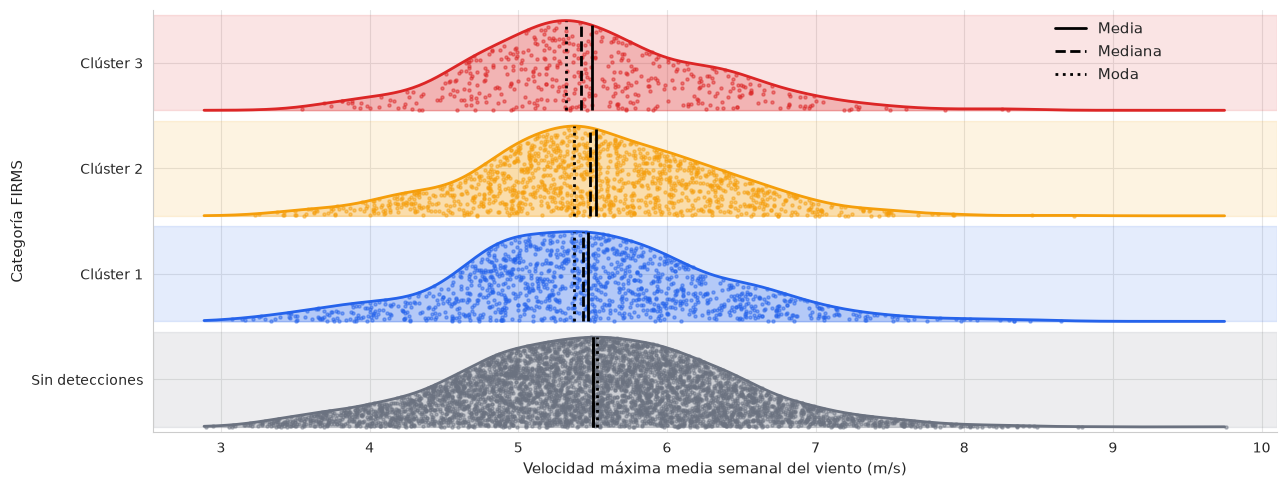

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
import numpy as np
from matplotlib.lines import Line2D


rng = np.random.default_rng(42)
#'mes', 'relative_humidity_2m_min_mean_weekly', 'wind_speed_10m_max_mean_weekly', 'precipitation_sum_weekly',
 #'cantidad_detecciones_lag1', 'cantidad_detecciones_lag2', 'cantidad_detecciones_lag3', 'cantidad_detecciones_lag4',
 #      'promedio_detecciones_ultimas_4_semanas',   'max_detecciones_ultimas_4_semanas', 'semanas_con_actividad_ultimas_4',
 #      'cantidad_detecciones', 'nivel_actividad_firms','nivel_actividad_firms_codigo'

variable = "wind_speed_10m_max_mean_weekly"

# Datos por cluster
v0 = data.loc[data["nivel_actividad_firms"] == "Sin detecciones", variable].dropna()
v1 = data.loc[data["nivel_actividad_firms"] == "Clúster 1", variable].dropna()
v2 = data.loc[data["nivel_actividad_firms"] == "Clúster 2", variable].dropna()
v3 = data.loc[data["nivel_actividad_firms"] == "Clúster 3", variable].dropna()


# Dispersión horizontal
# Dispersión horizontal
jitter_x = 0.02

x0 = v0.to_numpy() + rng.uniform(-jitter_x, jitter_x, len(v0))
x1 = v1.to_numpy() + rng.uniform(-jitter_x, jitter_x, len(v1))
x2 = v2.to_numpy() + rng.uniform(-jitter_x, jitter_x, len(v2))
x3 = v3.to_numpy() + rng.uniform(-jitter_x, jitter_x, len(v3))
# Valores del eje X
xx = np.linspace(
    min(v0.min(), v1.min(), v2.min(), v3.min()),
    max(v0.max(), v1.max(), v2.max(), v3.max()),
    500
)
# Densidades KDE
kde0 = gaussian_kde(v0)
kde1 = gaussian_kde(v1)
kde2 = gaussian_kde(v2)
kde3 = gaussian_kde(v3)

# Normalizar la altura de cada curva
d0 = kde0(xx)
d1 = kde1(xx)
d2 = kde2(xx)
d3 = kde3(xx)

d0 = d0 / d0.max() * 0.85
d1 = d1 / d1.max() * 0.85
d2 = d2 / d2.max() * 0.85
d3 = d3 / d3.max() * 0.85

# Altura de la curva KDE en la posición de cada punto
h0 = np.interp(x0, xx, d0, left=0, right=0)
h1 = np.interp(x1, xx, d1, left=0, right=0)
h2 = np.interp(x2, xx, d2, left=0, right=0)
h3 = np.interp(x3, xx, d3, left=0, right=0)

# Distribuir los puntos dentro de cada curva
y0 = -0.45 + rng.uniform(0, 1, len(v0)) * h0
y1 =  0.55 + rng.uniform(0, 1, len(v1)) * h1
y2 =  1.55 + rng.uniform(0, 1, len(v2)) * h2
y3 =  2.55 + rng.uniform(0, 1, len(v3)) * h3



fig, ax = plt.subplots(figsize=(13, 5))

# Franjas sombreadas por cluster
ax.axhspan(-0.45, 0.45, color=COLORS["Sin detecciones"], alpha=0.12)
ax.axhspan(0.55, 1.45, color=COLORS["Clúster 1"], alpha=0.12)
ax.axhspan(1.55, 2.45, color=COLORS["Clúster 2"], alpha=0.12)
ax.axhspan(2.55, 3.45, color=COLORS["Clúster 3"], alpha=0.12)

# Puntos
ax.scatter(x0, y0, s=5, alpha=0.45, color=COLORS["Sin detecciones"], zorder=3)
ax.scatter(x1, y1, s=5, alpha=0.45, color=COLORS["Clúster 1"], zorder=3)
ax.scatter(x2, y2, s=5, alpha=0.45, color=COLORS["Clúster 2"], zorder=3)
ax.scatter(x3, y3, s=5, alpha=0.45, color=COLORS["Clúster 3"], zorder=3)



# Distribuciones simétricas por cluster

# Sin detecciones
ax.fill_between(xx, -0.45, -0.45 + d0, color=COLORS["Sin detecciones"], alpha=0.25)
ax.plot(xx, -0.45 + d0, color=COLORS["Sin detecciones"], lw=2)

# Clúster 1
ax.fill_between(xx, 0.55, 0.55 + d1, color=COLORS["Clúster 1"], alpha=0.25)
ax.plot(xx, 0.55 + d1, color=COLORS["Clúster 1"], lw=2)

# Clúster 2
ax.fill_between(xx, 1.55, 1.55 + d2, color=COLORS["Clúster 2"], alpha=0.25)
ax.plot(xx, 1.55 + d2, color=COLORS["Clúster 2"], lw=2)

# Clúster 3
ax.fill_between(xx, 2.55, 2.55 + d3, color=COLORS["Clúster 3"], alpha=0.25)
ax.plot(xx, 2.55 + d3, color=COLORS["Clúster 3"], lw=2)


media0, mediana0 = v0.mean(), v0.median()
media1, mediana1 = v1.mean(), v1.median()
media2, mediana2 = v2.mean(), v2.median()
media3, mediana3 = v3.mean(), v3.median()

# Sin detecciones
ax.vlines(media0, -0.45, -0.45 + np.interp(media0, xx, d0),
          color="black", linewidth=2, zorder=5)

ax.vlines(mediana0, -0.45, -0.45 + np.interp(mediana0, xx, d0),
          color="black", linestyle="--", linewidth=2, zorder=5)

# Clúster 1
ax.vlines(media1, 0.55, 0.55 + np.interp(media1, xx, d1),
          color="black", linewidth=2, zorder=5)

ax.vlines(mediana1, 0.55, 0.55 + np.interp(mediana1, xx, d1),
          color="black", linestyle="--", linewidth=2, zorder=5)

# Clúster 2
ax.vlines(media2, 1.55, 1.55 + np.interp(media2, xx, d2),
          color="black", linewidth=2, zorder=5)

ax.vlines(mediana2, 1.55, 1.55 + np.interp(mediana2, xx, d2),
          color="black", linestyle="--", linewidth=2, zorder=5)

# Clúster 3
ax.vlines(media3, 2.55, 2.55 + np.interp(media3, xx, d3),
          color="black", linewidth=2, zorder=5)

ax.vlines(mediana3, 2.55, 2.55 + np.interp(mediana3, xx, d3),
          color="black", linestyle="--", linewidth=2, zorder=5)

# Modas estimadas mediante KDE
moda0 = xx[np.argmax(d0)]
moda1 = xx[np.argmax(d1)]
moda2 = xx[np.argmax(d2)]
moda3 = xx[np.argmax(d3)]

# Líneas verticales de moda
ax.vlines(moda0, -0.45, -0.45 + d0.max(),
          color="black", linestyle=":", linewidth=2, zorder=6)

ax.vlines(moda1, 0.55, 0.55 + d1.max(),
          color="black", linestyle=":", linewidth=2, zorder=6)

ax.vlines(moda2, 1.55, 1.55 + d2.max(),
          color="black", linestyle=":", linewidth=2, zorder=6)

ax.vlines(moda3, 2.55, 2.55 + d3.max(),
          color="black", linestyle=":", linewidth=2, zorder=6)
# Formato
ax.set_yticks([0, 1, 2, 3])
ax.set_yticklabels(["Sin detecciones", "Clúster 1", "Clúster 2", "Clúster 3"])

ax.set_ylim(-0.5, 3.5)
#ax.set_xlim(-1,50)

ax.set_xlabel("Velocidad máxima media semanal del viento (m/s)")
ax.set_ylabel("Categoría FIRMS")

ax.spines[["top", "right"]].set_visible(False)

leyenda = [
    Line2D([0], [0], color="black", lw=2, label="Media"),
    Line2D([0], [0], color="black", lw=2, ls="--", label="Mediana"),
    Line2D([0], [0], color="black", lw=2, ls=":", label="Moda")
]

ax.legend(
    handles=leyenda,
    loc="center",
    bbox_to_anchor=(0.85, 0.90),
    frameon=False
)
plt.savefig(    OUTPUT / "figura_09_distribucion_viento.png",    dpi=300,    bbox_inches="tight",    facecolor="white")
plt.tight_layout()
plt.show()

# MAPA

In [21]:
# El mapa se conserva como imagen; no requiere las fuentes FIRMS crudas locales.
mapa_original = OUTPUT / "auditoria/mapa_original_sin_cambios.png"
assert mapa_original.is_file(), "Falta la imagen original conservada del mapa."

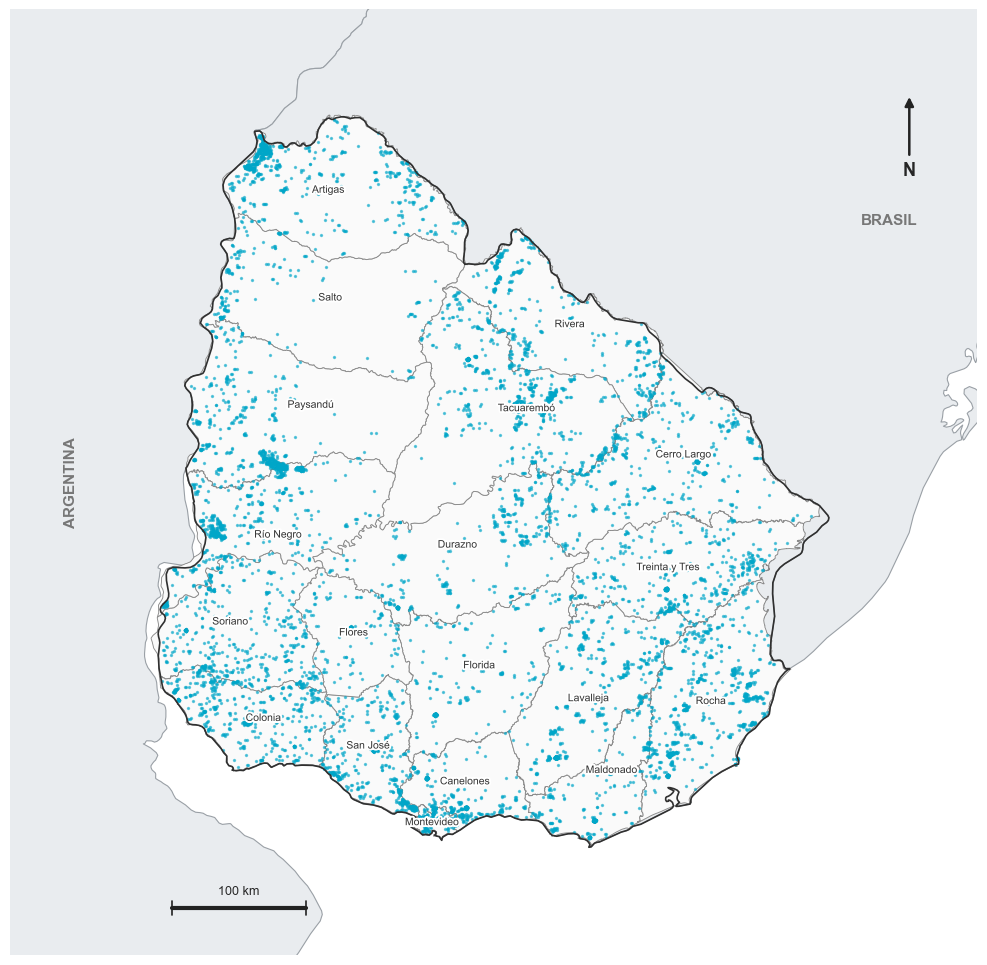

In [22]:
# El mapa no codifica clases. Se conserva exactamente la imagen original.
# La celda original y las referencias cartográficas están en la copia de auditoría.
# No descargar ni sustituir límites geográficos en una corrección de nomenclatura.
from IPython.display import Image, display
from shutil import copyfile
mapa = OUTPUT / "auditoria/mapa_original_sin_cambios.png"
copyfile(mapa, OUTPUT / "figura_01_mapa_firms_uruguay.png")
display(Image(filename=str(mapa)))